# Momentum Backtest

This notebook mirrors the current `algo_momentum.py` screening logic for a historical backtest.

- Prices are loaded from a CSV cache first.
- If a ticker is missing or the cached date range is incomplete, the notebook fetches missing data from `yfinance` and writes it back to the cache.
- Portfolio construction uses momentum ranking, a 100-day moving-average filter, a max daily gap filter, and inverse-volatility sizing.

The macro FRED filter is not included here by default; this backtest uses the price-based market regime filter only.

In [1]:
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

try:
    import yfinance as yf
except ImportError as exc:
    raise ImportError("Install `yfinance` before running this notebook: pip install yfinance") from exc

HAS_MATPLOTLIB = True

In [2]:


CACHE_DIR = Path("price_cache")
CACHE_DIR.mkdir(exist_ok=True)

START_DATE = pd.Timestamp("2010-01-01")
END_DATE = pd.Timestamp.today().normalize()
REBALANCE_FREQUENCY = "M"

MARKET_TICKER = "SPY"
TRADING_DAYS_IN_YEAR = 252
TREND_WINDOW_DAYS = 200
SLOPE_WINDOW_DAYS = 125
VOLA_WINDOW = 20
PORTFOLIO_SIZE = 20
MINIMUM_SCORE_MOMENTUM = 40.0
MAX_STOCK_GAP = 0.15
MA_WINDOW = 100
LOOKBACK_BUFFER_DAYS = 450

# Use a smaller manual universe while iterating, then switch to the full Wikipedia universe.
MANUAL_UNIVERSE = []
WIKI_SOURCES = ("500",)


In [3]:
def normalize_provider_symbol(symbol: str) -> str:
    return symbol.replace(".", "-")


def cache_paths_for_symbol(symbol: str, cache_dir: Path) -> list[Path]:
    provider_symbol = normalize_provider_symbol(symbol)
    paths = [cache_dir / f"{symbol}.csv"]
    if provider_symbol != symbol:
        paths.append(cache_dir / f"{provider_symbol}.csv")
    return paths


def standardize_price_frame(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return df

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    rename_map = {col: col.strip() for col in df.columns}
    df = df.rename(columns=rename_map)

    if "Date" not in df.columns:
        df = df.reset_index()

    required_columns = ["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"]
    for column in required_columns:
        if column not in df.columns:
            if column == "Adj Close" and "Close" in df.columns:
                df[column] = df["Close"]
            else:
                df[column] = np.nan

    df = df[required_columns].copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.dropna(subset=["Date"]).sort_values("Date").drop_duplicates(subset=["Date"], keep="last")
    numeric_columns = [col for col in required_columns if col != "Date"]
    df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")
    df = df.set_index("Date")
    return df


def read_cached_prices(symbol: str, cache_dir: Path) -> pd.DataFrame:
    for path in cache_paths_for_symbol(symbol, cache_dir):
        if path.exists():
            return standardize_price_frame(pd.read_csv(path))
    return pd.DataFrame()


def fetch_yfinance_prices(symbol: str, start_date: pd.Timestamp, end_date: pd.Timestamp) -> pd.DataFrame:
    provider_symbol = normalize_provider_symbol(symbol)
    download = yf.download(
        provider_symbol,
        start=start_date.strftime("%Y-%m-%d"),
        end=(end_date + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
        auto_adjust=False,
        progress=False,
    )
    if download.empty:
        return pd.DataFrame()
    return standardize_price_frame(download)


def load_price_history(symbol: str, cache_dir: Path, start_date: pd.Timestamp, end_date: pd.Timestamp, buffer_days: int = LOOKBACK_BUFFER_DAYS) -> pd.DataFrame:
    required_start = (pd.Timestamp(start_date) - pd.Timedelta(days=buffer_days)).normalize()
    required_end = pd.Timestamp(end_date).normalize()

    cached = read_cached_prices(symbol, cache_dir)
    cache_complete = (
        not cached.empty
        and cached.index.min() <= required_start
        and cached.index.max() >= required_end
    )

    if not cache_complete:
        fetched = fetch_yfinance_prices(symbol, required_start, required_end)
        if not fetched.empty:
            combined = fetched if cached.empty else pd.concat([cached, fetched])
            combined = standardize_price_frame(combined.reset_index())
            combined.reset_index().to_csv(cache_dir / f"{symbol}.csv", index=False)
            cached = combined

    if cached.empty:
        raise ValueError(f"No price history available for {symbol}")

    return cached.loc[(cached.index >= required_start) & (cached.index <= required_end)].copy()


WIKIPEDIA_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/123.0.0.0 Safari/537.36"
    )
}


def load_wikipedia_universe(sources=("500",)) -> list[str]:
    source_urls = {
        "500": "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies",
        "400": "https://en.wikipedia.org/wiki/List_of_S%26P_400_companies",
        "600": "https://en.wikipedia.org/wiki/List_of_S%26P_600_companies",
    }

    tickers: list[str] = []
    for source in sources:
        url = source_urls[source]
        response = requests.get(url, headers=WIKIPEDIA_HEADERS, timeout=30)
        response.raise_for_status()
        tables = pd.read_html(StringIO(response.text))
        table = next((table for table in tables if any(col in table.columns for col in ["Symbol", "Ticker symbol", "Ticker"])), None)
        if table is None:
            raise ValueError(f"Could not find ticker table for source {source}")

        ticker_column = next(col for col in ["Symbol", "Ticker symbol", "Ticker"] if col in table.columns)
        values = table[ticker_column].astype(str).str.strip().tolist()
        tickers.extend(values)

    # Preserve order while removing duplicates.
    return list(dict.fromkeys(tickers))


def momentum_score(ts: pd.Series, trading_days: int = TRADING_DAYS_IN_YEAR) -> float:
    ts = ts.dropna()
    if len(ts) < 2:
        return np.nan

    x = np.arange(len(ts))
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, np.log(ts))
    annualized_slope = (np.exp(slope) ** trading_days - 1) * 100
    return annualized_slope * (r_value ** 2)


def volatility(ts: pd.Series, vola_window: int = VOLA_WINDOW) -> float:
    ts = ts.dropna()
    if len(ts) < vola_window:
        return np.nan
    value = ts.pct_change().rolling(vola_window).std().mean()
    if pd.isna(value) or value <= 0:
        return np.nan
    return float(value)


def build_universe() -> list[str]:
    if MANUAL_UNIVERSE:
        return list(dict.fromkeys(MANUAL_UNIVERSE))
    return load_wikipedia_universe(WIKI_SOURCES)


In [4]:
universe = build_universe()
symbols = list(dict.fromkeys([MARKET_TICKER, *universe]))

price_frames: dict[str, pd.DataFrame] = {}
failed_symbols: dict[str, str] = {}

for symbol in symbols:
    try:
        price_frames[symbol] = load_price_history(symbol, CACHE_DIR, START_DATE, END_DATE)
    except Exception as exc:
        failed_symbols[symbol] = str(exc)

if MARKET_TICKER not in price_frames:
    raise ValueError(f"Market ticker {MARKET_TICKER} is required for the backtest")

if failed_symbols:
    print(f"Skipped {len(failed_symbols)} tickers with no data")
    display(pd.Series(failed_symbols).head(10).to_frame("error"))

adj_close = pd.concat({symbol: frame["Adj Close"] for symbol, frame in price_frames.items()}, axis=1).sort_index()
daily_returns = adj_close.pct_change()
market_close = adj_close[MARKET_TICKER].dropna()
trading_calendar = market_close.loc[(market_close.index >= START_DATE) & (market_close.index <= END_DATE)].index
rebalance_dates = market_close.resample(REBALANCE_FREQUENCY).last().loc[START_DATE:END_DATE].index

minimum_history = max(MA_WINDOW, SLOPE_WINDOW_DAYS, VOLA_WINDOW)


def select_portfolio(as_of_date: pd.Timestamp) -> tuple[dict[str, float], pd.DataFrame]:
    market_window = market_close.loc[:as_of_date].dropna().tail(TREND_WINDOW_DAYS)
    if len(market_window) < TREND_WINDOW_DAYS:
        return {}, pd.DataFrame()

    is_bull_market = market_window.iloc[-1] > market_window.mean()
    if not is_bull_market:
        return {}, pd.DataFrame()

    candidates = []
    for symbol in universe:
        series = adj_close[symbol].loc[:as_of_date].dropna().tail(TRADING_DAYS_IN_YEAR)
        if len(series) < minimum_history:
            continue
        if series.iloc[-1] <= series.tail(MA_WINDOW).mean():
            continue

        recent_returns = series.tail(SLOPE_WINDOW_DAYS).pct_change().abs()
        if (recent_returns > MAX_STOCK_GAP).any():
            continue

        score = momentum_score(series)
        if pd.isna(score) or score <= MINIMUM_SCORE_MOMENTUM:
            continue

        vol = volatility(series, VOLA_WINDOW)
        if pd.isna(vol) or vol <= 0:
            continue

        candidates.append(
            {
                "ticker": symbol,
                "score": score,
                "volatility": vol,
                "price": float(series.iloc[-1]),
            }
        )

    if not candidates:
        return {}, pd.DataFrame()

    ranking = pd.DataFrame(candidates).sort_values("score", ascending=False).head(PORTFOLIO_SIZE)
    inv_vol = 1 / ranking["volatility"]
    ranking["weight"] = inv_vol / inv_vol.sum()
    weights = ranking.set_index("ticker")["weight"].to_dict()
    return weights, ranking.reset_index(drop=True)


portfolio_returns = pd.Series(0.0, index=trading_calendar)
benchmark_returns = daily_returns[MARKET_TICKER].reindex(trading_calendar).fillna(0.0)
weights_history: list[dict[str, object]] = []
screen_history: list[pd.DataFrame] = []

for rebalance_date, next_rebalance_date in zip(rebalance_dates[:-1], rebalance_dates[1:]):
    weights, screen = select_portfolio(rebalance_date)
    weights_history.append({"date": rebalance_date, "weights": weights, "positions": len(weights)})

    if not screen.empty:
        screen = screen.copy()
        screen["date"] = rebalance_date
        screen_history.append(screen)

    period_index = trading_calendar[(trading_calendar > rebalance_date) & (trading_calendar <= next_rebalance_date)]
    if len(period_index) == 0:
        continue

    if not weights:
        portfolio_returns.loc[period_index] = 0.0
        continue

    weight_series = pd.Series(weights)
    period_returns = daily_returns.reindex(period_index)[weight_series.index].fillna(0.0)
    portfolio_returns.loc[period_index] = period_returns.mul(weight_series, axis=1).sum(axis=1)

equity_curve = (1 + portfolio_returns).cumprod()
benchmark_curve = (1 + benchmark_returns).cumprod()
drawdown = equity_curve / equity_curve.cummax() - 1


def performance_summary(returns: pd.Series) -> pd.Series:
    returns = returns.dropna()
    if returns.empty:
        return pd.Series(dtype=float)

    total_return = (1 + returns).prod() - 1
    years = max(len(returns) / TRADING_DAYS_IN_YEAR, 1 / TRADING_DAYS_IN_YEAR)
    cagr = (1 + total_return) ** (1 / years) - 1
    annual_vol = returns.std() * np.sqrt(TRADING_DAYS_IN_YEAR)
    sharpe = np.nan if annual_vol == 0 else returns.mean() / returns.std() * np.sqrt(TRADING_DAYS_IN_YEAR)
    max_dd = ((1 + returns).cumprod() / (1 + returns).cumprod().cummax() - 1).min()
    return pd.Series(
        {
            "Total Return": total_return,
            "CAGR": cagr,
            "Annual Volatility": annual_vol,
            "Sharpe": sharpe,
            "Max Drawdown": max_dd,
        }
    )


summary = pd.concat(
    {
        "Strategy": performance_summary(portfolio_returns),
        "Benchmark": performance_summary(benchmark_returns),
    },
    axis=1,
)

display(summary)
display(pd.DataFrame(weights_history).tail())

if screen_history:
    display(pd.concat(screen_history, ignore_index=True).tail(PORTFOLIO_SIZE))




/var/folders/nf/0f78fmr95hz6c9cwnjjzzdlr0000gp/T/ipykernel_58109/2535173725.py:21: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  daily_returns = adj_close.pct_change()
/var/folders/nf/0f78fmr95hz6c9cwnjjzzdlr0000gp/T/ipykernel_58109/2535173725.py:24: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  rebalance_dates = market_close.resample(REBALANCE_FREQUENCY).last().loc[START_DATE:END_DATE].index


,Strategy,Benchmark
Total Return,7.670800,6.889212
CAGR,0.142755,0.136105
Annual Volatility,0.182934,0.171598
Sharpe,0.821349,0.829830
Max Drawdown,-0.271543,-0.337173


,date,weights,positions
188,2025-09-30,"{'PLTR': 0.07679452317240552, 'HWM': 0.1319501...",8
189,2025-10-31,"{'NEM': 0.045318494183215575, 'APH': 0.0607251...",20
190,2025-11-30,"{'WDC': 0.03642952436463373, 'NEM': 0.04583235...",20
191,2025-12-31,"{'WDC': 0.03523793293256246, 'MU': 0.030770411...",20
192,2026-01-31,"{'MU': 0.028942050300434216, 'LRCX': 0.0357445...",20


,ticker,score,volatility,price,weight,date
2869,MU,308.161120,0.037297,414.880005,0.028942,2026-01-31
2870,LRCX,189.862955,0.030199,233.180634,0.035745,2026-01-31
2871,NEM,175.990550,0.025636,112.123085,0.042107,2026-01-31
2872,GOOGL,138.527807,0.016774,337.762238,0.064352,2026-01-31
2873,GOOG,135.308145,0.016480,338.291687,0.065502,2026-01-31
2874,CAT,121.100699,0.016030,657.359985,0.067340,2026-01-31
2875,APH,114.216487,0.016639,144.080002,0.064877,2026-01-31
2876,HII,111.747659,0.020120,419.200073,0.053651,2026-01-31
2877,ALB,96.058365,0.038653,170.630005,0.027927,2026-01-31
2878,INCY,90.236262,0.018351,100.070000,0.058821,2026-01-31


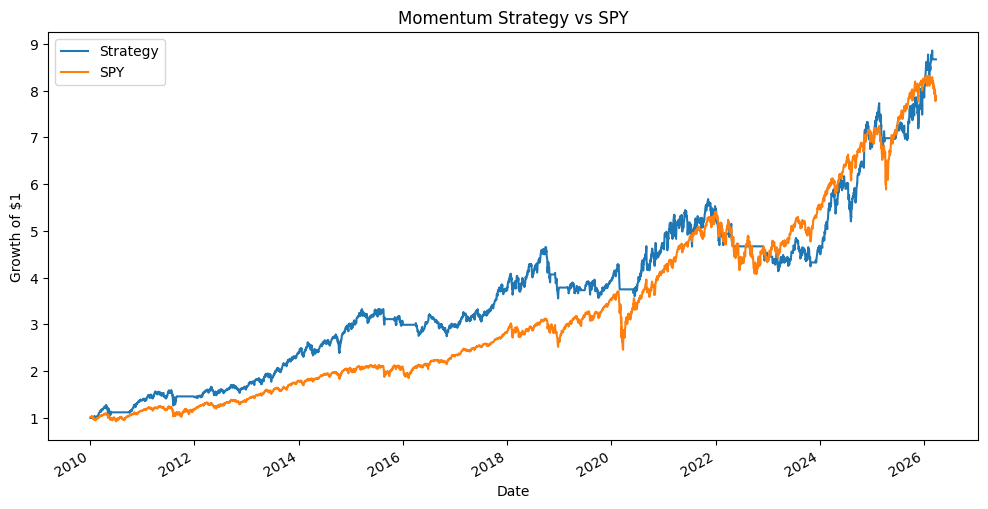

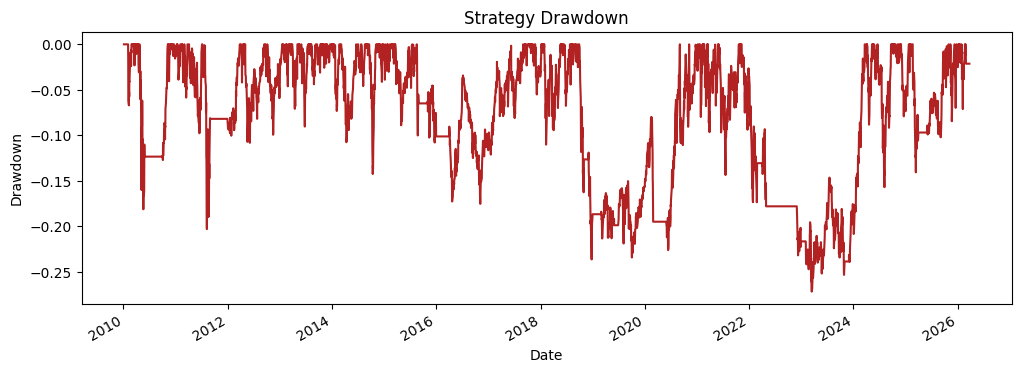

In [5]:
ax = equity_curve.plot(figsize=(12, 6), label="Strategy", title="Momentum Strategy vs SPY")
benchmark_curve.plot(ax=ax, label=MARKET_TICKER)
ax.set_ylabel("Growth of $1")
ax.legend()
plt.show()

ax = drawdown.plot(figsize=(12, 4), color="firebrick", title="Strategy Drawdown")
ax.set_ylabel("Drawdown")
plt.show()
